In [8]:
# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Loading data
filepath = 'C:/Users/ahedo/Documents/coding/Flotation/Data.csv'
df = pd.read_csv(filepath, parse_dates=[0], low_memory=False)
print(f"Original shape: {df.shape}")

# Converting all non-date columns to numeric values
date_col = df.columns[0]
numeric_cols = df.columns.drop(date_col)
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Handlig missing values using forward/backward fill
hourly_cols = ['% Iron Feed', '% Silica Feed', '% Iron Concentrate', '% Silica Concentrate']
df[hourly_cols] = df[hourly_cols].ffill().bfill()
df = df.interpolate(method='linear')
df = df.dropna()

print(f"After preprocessing: {df.shape}")

Original shape: (1048575, 24)
After preprocessing: (1048575, 24)


In [9]:
# Lag feature engineering (1h, 2h, 3h)
lag_cols = ['Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density',
            'Starch Flow', 'Amina Flow', '% Iron Feed', '% Silica Feed']

for col in lag_cols:
    for hours in [1, 2, 3]:
        df[f'{col}_lag_{hours}h'] = df[col].shift(hours * 60)

df = df.dropna()
print(f"After lag features: {df.shape}")
print(f"Total columns: {len(df.columns)}")


mask = (
    (df['% Iron Concentrate'].diff().abs() > 0) |
    (df['% Silica Concentrate'].diff().abs() > 0)
)
df_real = df[mask].copy()

print(f"Full dataset:              {len(df):,} rows")
print(f"Rows with real measurements: {len(df_real):,} rows")
print(f"Approx. one reading per:   {len(df) // len(df_real)} minutes")

After lag features: (1048395, 45)
Total columns: 45
Full dataset:              1,048,395 rows
Rows with real measurements: 3,418 rows
Approx. one reading per:   306 minutes


In [10]:
#Training libraries for normalisatiion
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

target_cols = ['% Iron Concentrate', '% Silica Concentrate']
feature_cols = [col for col in df.columns if col not in ['date'] + target_cols]

X = df[feature_cols]
y_iron = df['% Iron Concentrate']
y_silica = df['% Silica Concentrate']

split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx]
X_test  = X.iloc[split_idx:]

y_iron_train  = y_iron.iloc[:split_idx]
y_iron_test   = y_iron.iloc[split_idx:]

y_silica_train = y_silica.iloc[:split_idx]
y_silica_test  = y_silica.iloc[split_idx:]

print(f"Train: {X_train.shape} | covers first 80% of timeline")
print(f"Test:  {X_test.shape}  | covers final 20% of timeline")


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Features: {len(feature_cols)}")
print(f"Train: {X_train_scaled.shape}, Test: {X_test_scaled.shape}")

Train: (838716, 42) | covers first 80% of timeline
Test:  (209679, 42)  | covers final 20% of timeline
Features: 42
Train: (838716, 42), Test: (209679, 42)


In [11]:
#Machine learning Model for prediction
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

targets = {
    '% Iron Concentrate': (y_iron_train, y_iron_test),
    '% Silica Concentrate': (y_silica_train, y_silica_test)
}

models = {}
results = []

for target_name, (y_train, y_test) in targets.items():
    print(f"\nTraining: {target_name}")
    #Learning algorithms and   HYPERPARAMETERS
    model = xgb.XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0
    )
    
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    models[target_name] = model
    results.append({'Target': target_name, 'RMSE': round(rmse, 4), 'MAE': round(mae, 4), 'R² Score': round(r2, 4)})

print("\n" + "="*60)
print("FINAL RESULTS")
print("="*60)
print(pd.DataFrame(results).to_string(index=False))


Training: % Iron Concentrate

Training: % Silica Concentrate

FINAL RESULTS
              Target   RMSE  MAE      R² Score
  % Iron Concentrate 0.0082  0.0 -0.000000e+00
% Silica Concentrate 0.0000  0.0 -2.439582e+17


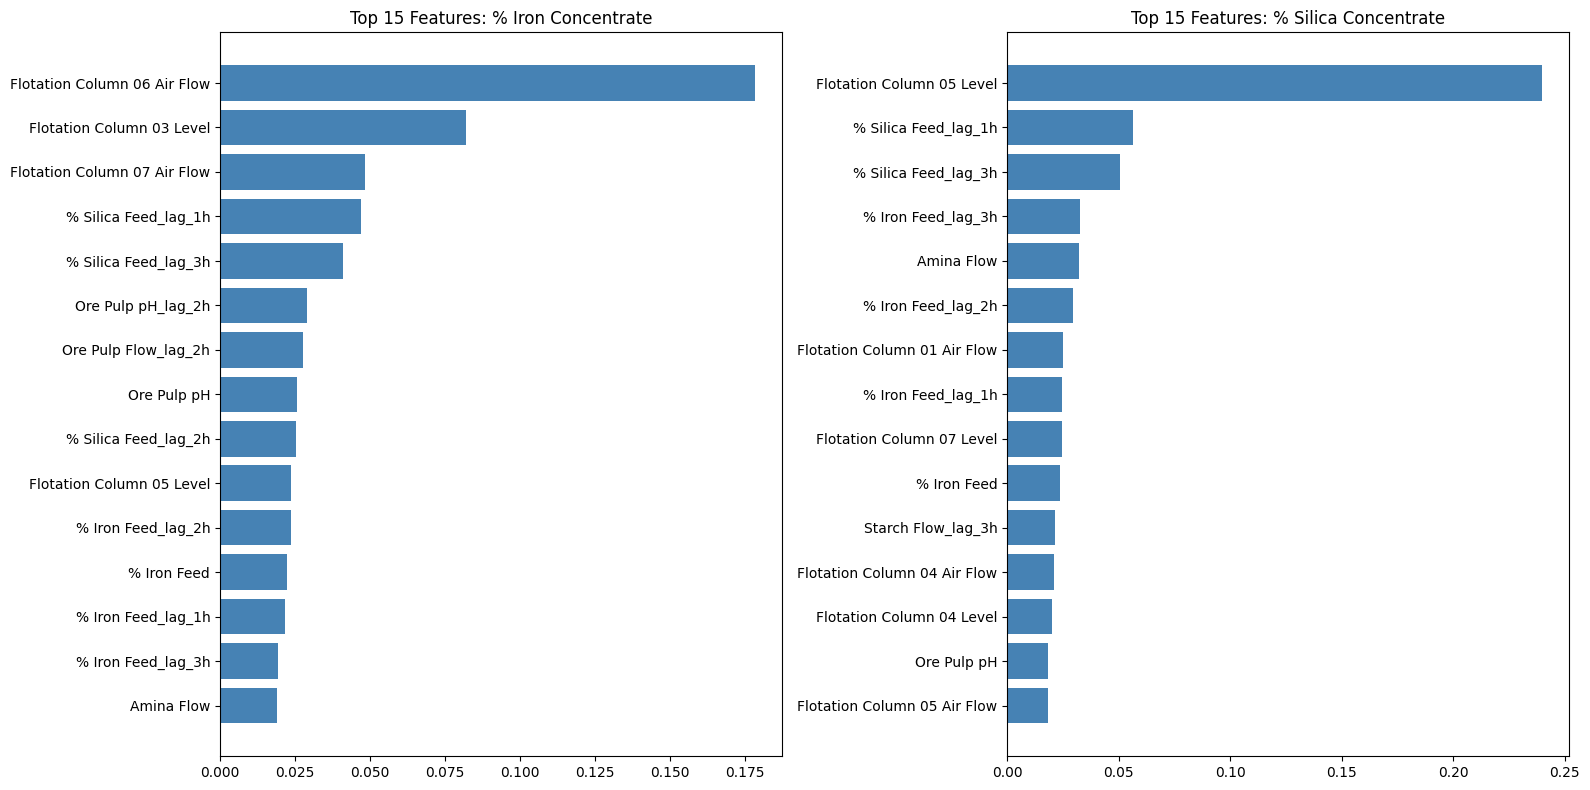

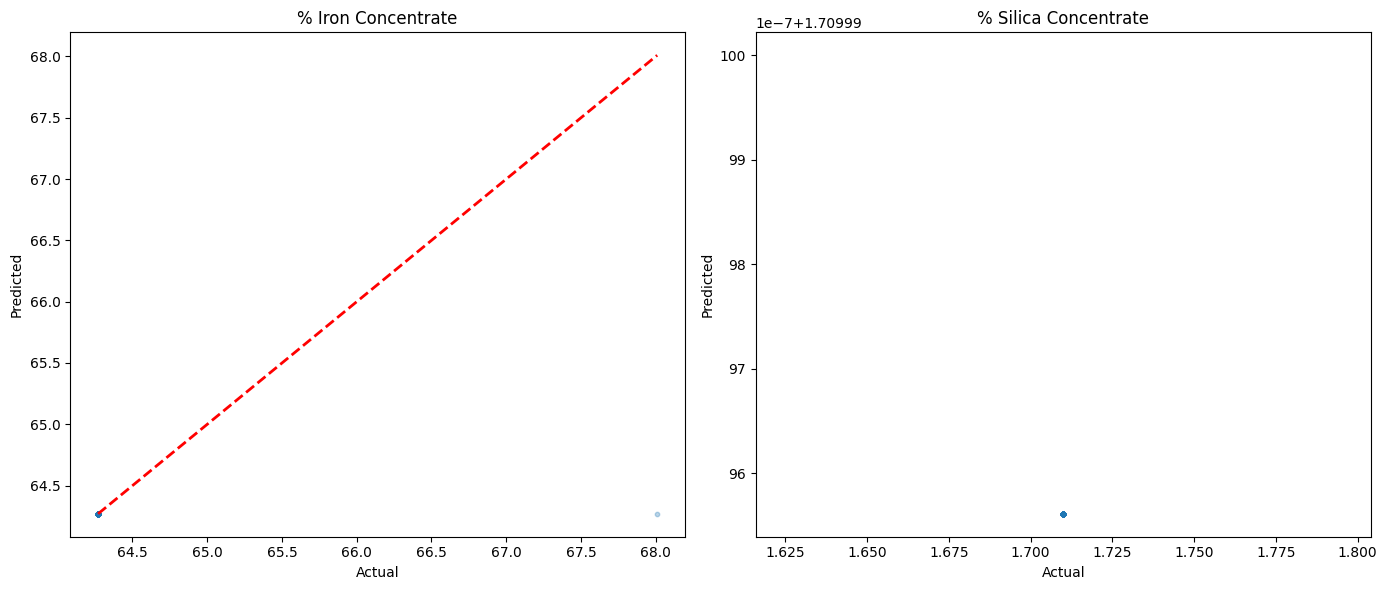


Models saved: xgb_iron_model.pkl, xgb_silica_model.pkl, scaler.pkl


In [12]:
import joblib

# Feature importance
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, (name, model) in zip(axes, models.items()):
    imp = pd.DataFrame({'Feature': feature_cols, 'Importance': model.feature_importances_})
    imp = imp.sort_values('Importance', ascending=True).tail(15)
    ax.barh(imp['Feature'], imp['Importance'], color='steelblue')
    ax.set_title(f'Top 15 Features: {name}')
plt.tight_layout()
plt.show()

# Actual vs Predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, (_, y_test)) in zip(axes, targets.items()):
    y_pred = models[name].predict(X_test_scaled)
    ax.scatter(y_test, y_pred, alpha=0.3, s=10)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_xlabel(f'Actual')
    ax.set_ylabel(f'Predicted')
    ax.set_title(name)
plt.tight_layout()
plt.show()

# Save models
joblib.dump(models['% Iron Concentrate'], 'xgb_iron_model.pkl')
joblib.dump(models['% Silica Concentrate'], 'xgb_silica_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("\nModels saved: xgb_iron_model.pkl, xgb_silica_model.pkl, scaler.pkl")

In [13]:
What does the Feature Importance tell us?

As a Plant Operator:
# When I see the model predicting silica is about to spike, 
# I know I have 1-2 hours to adjust reagent flows before it actually happens. 
# The model gives me a heads-up.

As a Process Engineer: 
#The feature importance tells me that pH and pulp density 
# in the past 2 hours are driving my concentrate quality. 
# I should focus my optimization efforts there, not on variables that barely register.

As a Plant Manager:
#With 64% accuracy, this model won't replace my operators, 
# but it's a valuable 'second opinion' that catches things humans might miss during a busy shift

SyntaxError: invalid syntax (3589314006.py, line 3)

In [ ]:
Why didn't the model capture the 35% of the variance?

#Ore variability that sensors don't capture
#Equipment wear that slowly changes behavior
#Unmeasured variables (temperature, operator decisions, etc.)
#Natural randomness in the flotation process
